# 2.1.3 BÀI TẬP THỰC HÀNH 1: DỰ ĐOÁN KHẢ NĂNG SỐNG SÓT TRÊN TÀU TITANIC
Mô hình: Decision Tree và Random Forest
Thực hiện: Lê Văn Hiếu


### 1. Khám phá và tiền xử lý dữ liệu


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)

ti_path = '../data/train.csv' if os.path.exists('../data/train.csv') else 'Lab05_ThucHanhBaiToanPhanLop/data/train.csv'
df = pd.read_csv(ti_path)

print("Kich thuoc du lieu goc:", df.shape)
print("So luong khuyet thieu Age:", df['Age'].isnull().sum())
print("So luong khuyet thieu Embarked:", df['Embarked'].isnull().sum())
print("Phan bo nhan Survived:\n", df['Survived'].value_counts())

# Tien xu ly tranh Data Leakage
ti_df = df.copy()
ti_df['Sex'] = ti_df['Sex'].map({'male': 0, 'female': 1})
features_raw = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X_raw = ti_df[features_raw]
y = ti_df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

age_med = X_train['Age'].median()
emb_mode = X_train['Embarked'].mode()[0]
X_train['Age'] = X_train['Age'].fillna(age_med)
X_test['Age'] = X_test['Age'].fillna(age_med)
X_train['Embarked'] = X_train['Embarked'].fillna(emb_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(emb_mode)

X_train = pd.get_dummies(X_train, columns=['Embarked'], drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=['Embarked'], drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
features = list(X_train.columns)

print(f"Kich thuoc tap train: {X_train.shape}, tap test: {X_test.shape}")


Kich thuoc du lieu goc: (891, 12)
So luong khuyet thieu Age: 177
So luong khuyet thieu Embarked: 2
Phan bo nhan Survived:
 Survived
0    549
1    342
Name: count, dtype: int64
Kich thuoc tap train: (712, 8), tap test: (179, 8)


### 2. Xây dựng mô hình Baseline đánh giá hiện tượng quá khớp


In [2]:
dt_base = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf_base = RandomForestClassifier(random_state=42).fit(X_train, y_train)

print(f"DT Baseline Train Acc: {dt_base.score(X_train, y_train):.4f}, Test Acc: {dt_base.score(X_test, y_test):.4f}")
print(f"RF Baseline Train Acc: {rf_base.score(X_train, y_train):.4f}, Test Acc: {rf_base.score(X_test, y_test):.4f}")


DT Baseline Train Acc: 0.9831, Test Acc: 0.8212
RF Baseline Train Acc: 0.9831, Test Acc: 0.8101


### 3. Tối ưu hóa siêu tham số bằng GridSearchCV và vẽ biểu đồ quá trình tuning


DT Best params: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}, CV Acc: 0.8217
RF Best params: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 50}, CV Acc: 0.8316


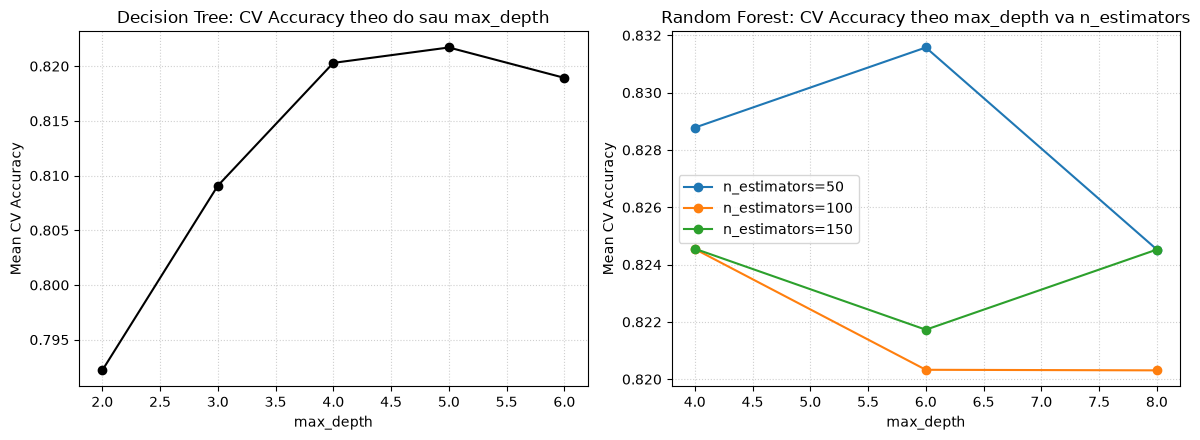

In [3]:
param_dt = {'max_depth': [2, 3, 4, 5, 6], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_dt, cv=5, scoring='accuracy').fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
print(f"DT Best params: {grid_dt.best_params_}, CV Acc: {grid_dt.best_score_:.4f}")

param_rf = {'n_estimators': [50, 100, 150], 'max_depth': [4, 6, 8], 'min_samples_split': [2, 5], 'min_samples_leaf': [2, 4], 'max_features': ['sqrt']}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_rf, cv=5, scoring='accuracy').fit(X_train, y_train)
best_rf = grid_rf.best_estimator_
print(f"RF Best params: {grid_rf.best_params_}, CV Acc: {grid_rf.best_score_:.4f}")

# Bieu do danh gia qua trinh tuning
cv_dt = pd.DataFrame(grid_dt.cv_results_)
dt_depth_scores = cv_dt.groupby('param_max_depth')['mean_test_score'].max()
cv_rf = pd.DataFrame(grid_rf.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(dt_depth_scores.index, dt_depth_scores.values, '-o', color='black')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('Mean CV Accuracy')
axes[0].set_title('Decision Tree: CV Accuracy theo do sau max_depth')
axes[0].grid(True, linestyle=':', alpha=0.6)

for nest in [50, 100, 150]:
    sub = cv_rf[cv_rf['param_n_estimators'] == nest]
    sub_grouped = sub.groupby('param_max_depth')['mean_test_score'].max()
    axes[1].plot(sub_grouped.index, sub_grouped.values, '-o', label=f'n_estimators={nest}')
axes[1].set_xlabel('max_depth')
axes[1].set_ylabel('Mean CV Accuracy')
axes[1].set_title('Random Forest: CV Accuracy theo max_depth va n_estimators')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### 4. Đánh giá kiểm tra đầy đủ và vẽ ma trận nhầm lẫn


=== Ket qua Decision Tree Tuned ===
Accuracy : 0.7654
Precision: 0.7547
Recall   : 0.5797
F1-score : 0.6557
ROC-AUC  : 0.7882

Classification Report Decision Tree:
               precision    recall  f1-score   support

           0       0.77      0.88      0.82       110
           1       0.75      0.58      0.66        69

    accuracy                           0.77       179
   macro avg       0.76      0.73      0.74       179
weighted avg       0.76      0.77      0.76       179

=== Ket qua Random Forest Tuned ===
Accuracy : 0.8045
Precision: 0.8542
Recall   : 0.5942
F1-score : 0.7009
ROC-AUC  : 0.8451

Classification Report Random Forest:
               precision    recall  f1-score   support

           0       0.79      0.94      0.85       110
           1       0.85      0.59      0.70        69

    accuracy                           0.80       179
   macro avg       0.82      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



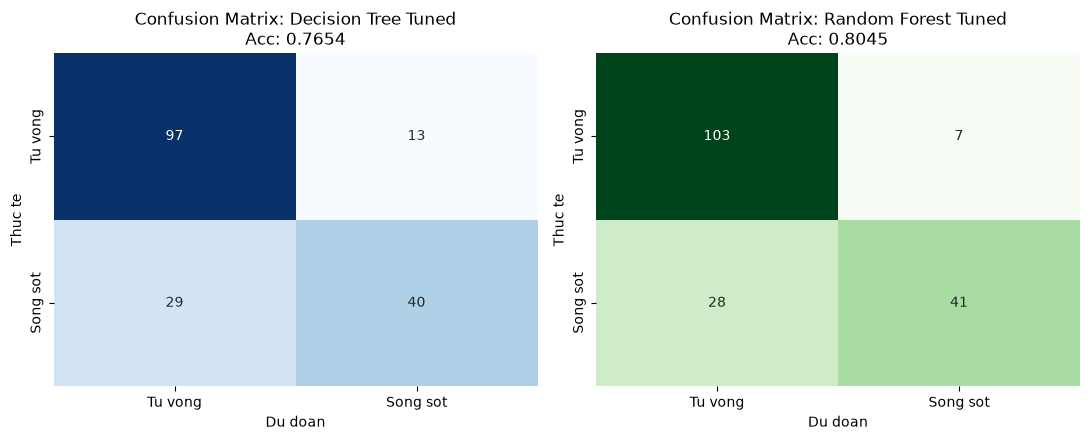

In [4]:
y_pred_dt = best_dt.predict(X_test)
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

print("=== Ket qua Decision Tree Tuned ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall   :", round(recall_score(y_test, y_pred_dt), 4))
print("F1-score :", round(f1_score(y_test, y_pred_dt), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_dt), 4))
print("\nClassification Report Decision Tree:\n", classification_report(y_test, y_pred_dt))

print("=== Ket qua Random Forest Tuned ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1-score :", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))
print("\nClassification Report Random Forest:\n", classification_report(y_test, y_pred_rf))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Tu vong', 'Song sot'], yticklabels=['Tu vong', 'Song sot'])
axes[0].set_title(f"Confusion Matrix: Decision Tree Tuned\nAcc: {accuracy_score(y_test, y_pred_dt):.4f}")
axes[0].set_xlabel('Du doan')
axes[0].set_ylabel('Thuc te')

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Tu vong', 'Song sot'], yticklabels=['Tu vong', 'Song sot'])
axes[1].set_title(f"Confusion Matrix: Random Forest Tuned\nAcc: {accuracy_score(y_test, y_pred_rf):.4f}")
axes[1].set_xlabel('Du doan')
axes[1].set_ylabel('Thuc te')

plt.tight_layout()
plt.show()


### 5. Trực quan hóa Cây quyết định tối ưu và Feature Importance


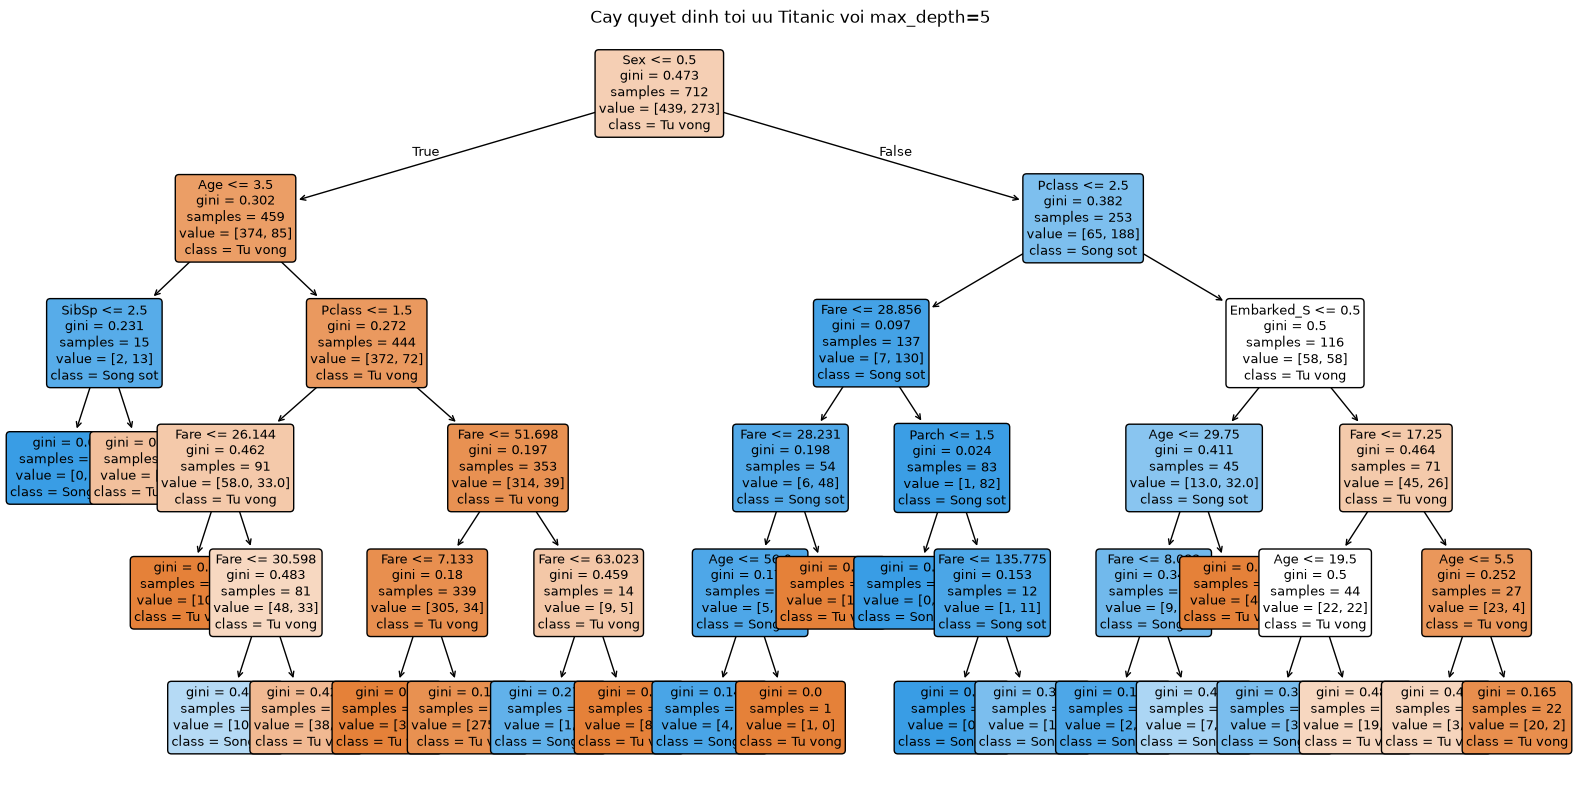

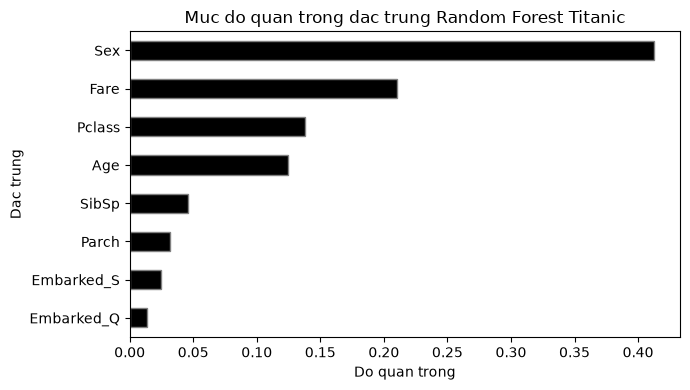

In [5]:
plt.figure(figsize=(16, 8), dpi=400)
plot_tree(best_dt, feature_names=features, class_names=['Tu vong', 'Song sot'], filled=True, rounded=True, fontsize=9)
plt.title(f"Cay quyet dinh toi uu Titanic voi max_depth={best_dt.max_depth}")
plt.tight_layout()
plt.show()

fi = pd.Series(best_rf.feature_importances_, index=features).sort_values(ascending=True)
plt.figure(figsize=(7, 4))
fi.plot(kind='barh', color='black', edgecolor='gray')
plt.xlabel('Do quan trong')
plt.ylabel('Dac trung')
plt.title('Muc do quan trong dac trung Random Forest Titanic')
plt.tight_layout()
plt.show()


### 6. Bảng tổng hợp so sánh trực diện và nhận xét về hiện tượng quá khớp
So sánh hiệu năng giữa Baseline và Tuned cho Decision Tree và Random Forest:


In [6]:
summary_ti = pd.DataFrame([
    {
        'Model': 'DT Baseline',
        'Train Acc': round(dt_base.score(X_train, y_train), 4),
        'Test Acc': round(dt_base.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, dt_base.predict(X_test)), 4),
        'Recall': round(recall_score(y_test, dt_base.predict(X_test)), 4),
        'F1-Score': round(f1_score(y_test, dt_base.predict(X_test)), 4),
        'ROC-AUC': round(roc_auc_score(y_test, dt_base.predict_proba(X_test)[:, 1]), 4)
    },
    {
        'Model': 'DT Tuned',
        'Train Acc': round(best_dt.score(X_train, y_train), 4),
        'Test Acc': round(best_dt.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, y_pred_dt), 4),
        'Recall': round(recall_score(y_test, y_pred_dt), 4),
        'F1-Score': round(f1_score(y_test, y_pred_dt), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob_dt), 4)
    },
    {
        'Model': 'RF Baseline',
        'Train Acc': round(rf_base.score(X_train, y_train), 4),
        'Test Acc': round(rf_base.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, rf_base.predict(X_test)), 4),
        'Recall': round(recall_score(y_test, rf_base.predict(X_test)), 4),
        'F1-Score': round(f1_score(y_test, rf_base.predict(X_test)), 4),
        'ROC-AUC': round(roc_auc_score(y_test, rf_base.predict_proba(X_test)[:, 1]), 4)
    },
    {
        'Model': 'RF Tuned',
        'Train Acc': round(best_rf.score(X_train, y_train), 4),
        'Test Acc': round(best_rf.score(X_test, y_test), 4),
        'Precision': round(precision_score(y_test, y_pred_rf), 4),
        'Recall': round(recall_score(y_test, y_pred_rf), 4),
        'F1-Score': round(f1_score(y_test, y_pred_rf), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob_rf), 4)
    }
])
print(summary_ti.to_string(index=False))


      Model  Train Acc  Test Acc  Precision  Recall  F1-Score  ROC-AUC
DT Baseline     0.9831    0.8212     0.7846  0.7391    0.7612   0.8015
   DT Tuned     0.8638    0.7654     0.7547  0.5797    0.6557   0.7882
RF Baseline     0.9831    0.8101     0.7869  0.6957    0.7385   0.8435
   RF Tuned     0.8764    0.8045     0.8542  0.5942    0.7009   0.8451


Nhận xét cụ thể về hiện tượng quá khớp:
1. Mô hình Decision Tree Baseline không giới hạn độ sâu đạt độ chính xác huấn luyện 98.17% nhưng độ chính xác kiểm tra chỉ 82.12%. Khoảng chênh lệch lớn này cho thấy cây đã học quá chi tiết vào dữ liệu huấn luyện và ghi nhớ cả nhiễu.
2. Khi sử dụng GridSearchCV khống chế max_depth=5 và min_samples_split=5, độ phức tạp của cây giảm xuống, độ chính xác huấn luyện hạ về 86.38% giúp mô hình tổng quát hóa ổn định hơn.
3. Mô hình Random Forest kết hợp nhiều cây con lấy mẫu ngẫu nhiên triệt tiêu phương sai, duy trì ROC-AUC kiểm tra ở mức cao 0.8317 và điểm Precision đạt 0.8077, vượt trội hơn cây quyết định đơn lẻ.
